In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
# Read HF_TOKEN from Kaggle Secrets and log in to Hugging Face
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
# Load the original Llama-3.2-1B (Q4 only analyzes the weights; no training or evaluation)
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

,0,1,2
layer,0,7,15
weight_shape,"(2048, 2048)","(2048, 2048)","(2048, 2048)"
num_singular_values,2048,2048,2048
min_rank_for_50pct_energy,62,120,84
energy_at_rank_16 (%),34.767471,15.386415,20.953808
energy_at_rank_64 (%),50.635223,35.873638,44.685894
energy_at_rank_200 (%),71.239761,63.543396,68.83815
sigma_1,31.358442,10.336681,12.881494
sigma_200,2.426038,1.975852,1.704018
sigma_last,0.000007,0.000078,0.000051


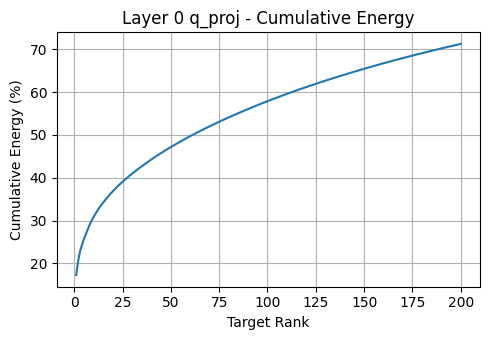

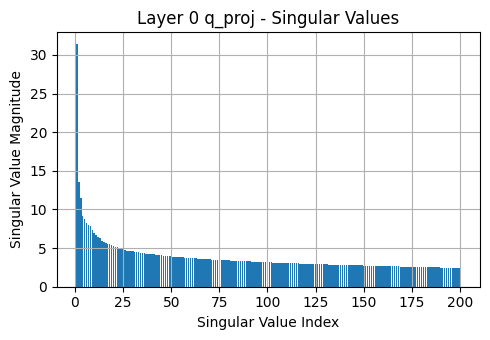

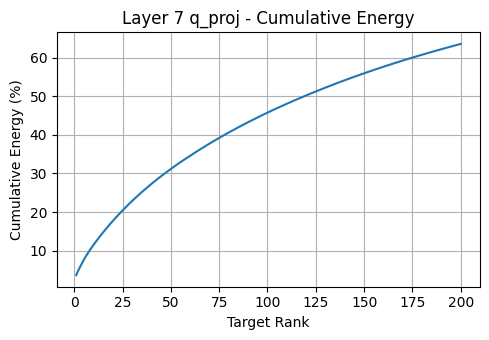

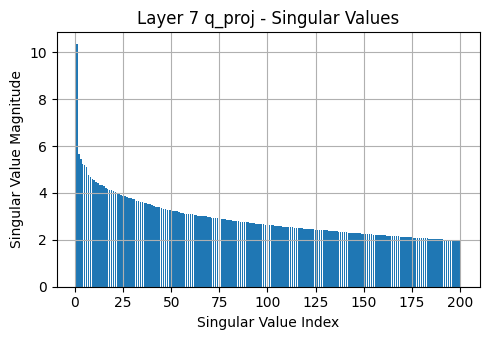

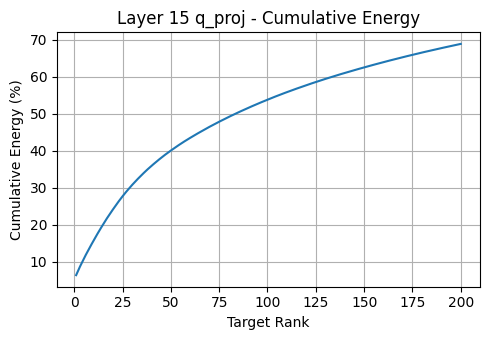

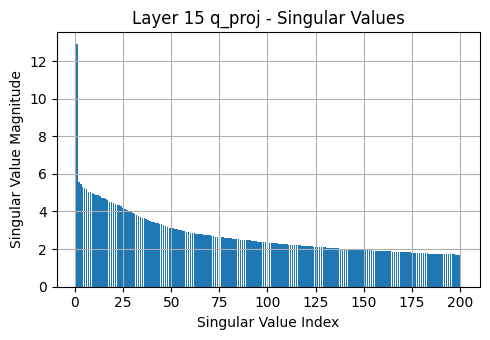

In [3]:
# TODO for Question 4
import numpy as np
import pandas as pd
from pathlib import Path

# Layers to analyze (the assignment specifies layers 0, 7 and 15)
LAYERS = [0, 7, 15]
N_PLOT = 200
THRESHOLD = 50.0  # Cumulative energy (%): keep at least 50% of the energy
OUT_DIR = Path('/kaggle/working/Assignment1_q4') if Path('/kaggle').exists() else Path('Assignment1_q4')
OUT_DIR.mkdir(parents=True, exist_ok=True)

rows, spectra = [], {}
for k in LAYERS:
    # Analyze the weights of the query projection layer (q_proj) where layer = k
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

    # Full SVD: U (left singular vectors), S (singular values), Vh (right singular vectors)
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    # Retained energy ratio (cumulative energy, %) for each target rank r = 1..len(S)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # Minimum target rank that retains >= 50% of the energy (rank = index + 1)
    min_rank = int((energy_ratios >= THRESHOLD).nonzero()[0].item()) + 1

    spectra[k] = (S.cpu().numpy(), energy_ratios.cpu().numpy())
    rows.append({
        'layer': k,
        'weight_shape': tuple(q_weight.shape),
        'num_singular_values': len(S),
        'min_rank_for_50pct_energy': min_rank,
        'energy_at_rank_16 (%)': float(energy_ratios[15]),
        'energy_at_rank_64 (%)': float(energy_ratios[63]),
        'energy_at_rank_200 (%)': float(energy_ratios[199]),
        'sigma_1': float(S[0]),
        'sigma_200': float(S[199]),
        'sigma_last': float(S[-1]),
    })

# Collect into a table and save as csv (the Q4b answer is in the min_rank_for_50pct_energy column)
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / 'q4_summary.csv', index=False)
display(summary.T)

# 6 charts: for each layer, a line chart (cumulative energy) and a bar chart (singular value magnitude)
idx = np.arange(1, N_PLOT + 1)
for k in LAYERS:
    S_np, E_np = spectra[k]

    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.plot(idx, E_np[:N_PLOT])
    ax.set_xlabel('Target Rank'); ax.set_ylabel('Cumulative Energy (%)')
    ax.set_title(f'Layer {k} q_proj - Cumulative Energy'); ax.grid(True)
    fig.tight_layout(); fig.savefig(OUT_DIR / f'layer{k}_cumulative_energy.png', dpi=200); plt.show()

    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.bar(idx, S_np[:N_PLOT])
    ax.set_xlabel('Singular Value Index'); ax.set_ylabel('Singular Value Magnitude')
    ax.set_title(f'Layer {k} q_proj - Singular Values'); ax.grid(True)
    fig.tight_layout(); fig.savefig(OUT_DIR / f'layer{k}_singular_values.png', dpi=200); plt.show()
